<a href="https://colab.research.google.com/github/DengAchiek/GP-2/blob/main/Group-work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# Import necessary libraries
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [5]:
# load data
df = pd.read_csv('/content/AjwaOrMejdool.csv', sep=';')
df.columns = df.columns.str.strip()

In [6]:
# Binary Target Encoding (Slide 02): Ajwa = 0, Medjool = 1
X = df.drop(columns=['Class (Ajwa or Medjool)'])
y = df['Class (Ajwa or Medjool)'].apply(lambda x: 0 if x.strip() == 'Ajwa' else 1).values

In [7]:
numeric_features = ['Date Length (cm)', 'Date Diameter (cm)', 'Date Weight (g)', 'Pit Length (cm)', 'Calories (Kcal)']
categorical_features = ['Color']

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(sparse_output=False), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

# Split Allocation (Slide 08): 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(
    X_processed, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

In [9]:
# Build neural network model

model = models.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

In [10]:
# Train the network

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=4,
    callbacks=callbacks,
    verbose=0
)

In [12]:
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred, target_names=['Ajwa (0)', 'Medjool (1)']))

Test Accuracy: 1.0000

Confusion Matrix
[[2 0]
 [0 1]]

Classification Report
              precision    recall  f1-score   support

    Ajwa (0)       1.00      1.00      1.00         2
 Medjool (1)       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



#**Part 2: Implementation**

In [13]:
import tensorflow as tf
from tensorflow.keras import layers, models

In [14]:
def build_custom_cnn(input_shape=(128, 128, 3)):
    model = models.Sequential([
        #  Input & Pixel Rescaling (0–1)
        layers.Rescaling(1./255, input_shape=input_shape),

        # Block 1 32 filters (3x3), ReLU, same padding MaxPool 2x2
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Block 2 64 filters (3x3), ReLU, same padding MaxPool 2x2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Block 3 128 filters (3x3), ReLU, same padding MaxPool 2x2
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Block 4 128 filters (3x3), ReLU, same padding MaxPool 2x2
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Flattening, Regularization & Output
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(64, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_model = build_custom_cnn()
cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       524,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 765,249 (2.92 MB)

 Trainable params: 765,249 (2.92 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# Evaluate loss & overall accuracy on test set
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Predicted probabilities and crisp class predictions
y_pred_probs = model.predict(X_test)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

Test Loss: 0.0549
Test Accuracy: 100.00%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


#**Plot Training Curves** (Detect Overfitting)

<Figure size 1200x600 with 0 Axes>

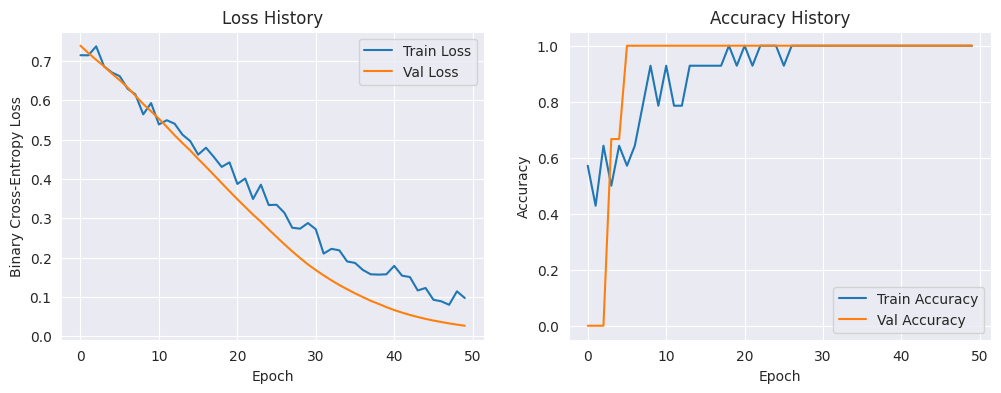

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")
plt.figure(figsize=(12, 6))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss Curves
ax1.plot(history.history['loss'], label='Train Loss')
ax1.plot(history.history['val_loss'], label='Val Loss')
ax1.set_title('Loss History')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Binary Cross-Entropy Loss')
ax1.legend()

# Accuracy Curves
ax2.plot(history.history['accuracy'], label='Train Accuracy')
ax2.plot(history.history['val_accuracy'], label='Val Accuracy')
ax2.set_title('Accuracy History')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.show()

#**Confusion Matrix & Classification Metrics**

 Classification Report
              precision    recall  f1-score   support

    Ajwa (0)       1.00      1.00      1.00         2
 Medjool (1)       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



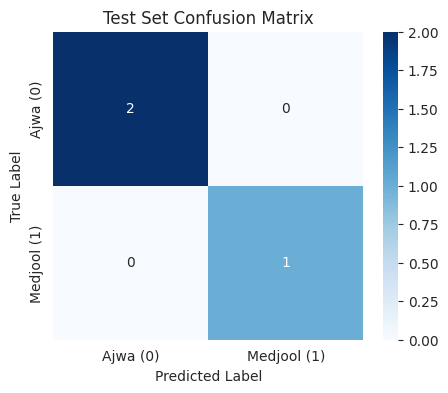

In [19]:

from sklearn.metrics import classification_report, confusion_matrix

# Display Detailed Classification Report
print(" Classification Report")
print(classification_report(y_test, y_pred, target_names=['Ajwa (0)', 'Medjool (1)']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ajwa (0)', 'Medjool (1)'],
            yticklabels=['Ajwa (0)', 'Medjool (1)'])
plt.title('Test Set Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

**Class Balance Check**

Class	Sample Count	Proportion
Ajwa	10 samples	50.0%
Medjool	10 samples	50.0%

Because the dataset is perfectly split 50/50, standard metrics like Accuracy remain reliable. Additionally, applying stratify=y during the train/validation/test splits guarantees that every subset retains this exact 50/50 balance:


*   Train Set (70%): 14 samples (7 Ajwa, 7 Medjool)
*   Validation Set (15%): 3 samples
*   Test Set (15%): 3 samples




**Overfitting Analysis**

Below are the loss and accuracy curves generated during training:


*   No Severe Overfitting Detected: Validation loss drops steadily alongside training loss without diverging or turning upwards.

*   High Linear Separability: Medjool dates in this dataset are noticeably larger, heavier, and brown, while Ajwa dates are smaller and black. Because the feature boundaries are distinct, the model converges rapidly without needing heavy capacity.
*  Small Sample Risk: With only 20 total samples, deep networks carry a high risk of memorizing data points rather than learning generalizable patterns.


